# Step 1 - Plan and understand the data  (20 Sep - 3 Oct)
Proposal objectives 1 and 3. Checks columns, labels, missing values, duplicates and class balance, whether every NC State transcript is usable, and decides how a call is paired with a message, email or link.

In [1]:
import sys
from pathlib import Path
sys.path.insert(0, str(Path.cwd().parent))
import pandas as pd
pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 30)
from toadwatch import config as C
from toadwatch.data_loading import load_calls, load_messages, load_nc_state_calls
from toadwatch.pipeline import audit_table
from toadwatch.reporting import plot_class_balance
calls = load_calls(); msgs = load_messages()
len(calls), len(msgs)

(8952, 167759)

## Are all NC State transcripts usable?

In [2]:
nc = load_nc_state_calls()
nc['chars'] = nc.text.str.len()
print('transcripts:', len(nc), '| languages:', nc.lang.value_counts().to_dict())
print('shorter than', C.MIN_TRANSCRIPT_CHARS, 'chars:', (nc.chars < C.MIN_TRANSCRIPT_CHARS).sum())
print('exact duplicate transcripts (robocall templates):', nc.text.duplicated().sum())
nc.chars.describe()

transcripts: 1432 | languages: {'en': 1378, 'zh': 54}
shorter than 20 chars: 0
exact duplicate transcripts (robocall templates): 575


count    1432.000000
mean      336.867318
std       263.573811
min        31.000000
25%       234.000000
50%       296.000000
75%       395.250000
max      7154.000000
Name: chars, dtype: float64

Non-English transcripts (Chinese) are excluded because the keyword features are English/Spanish; repeated robocall scripts are removed in Step 2.

## Columns, labels, missing values, duplicates - calls

In [3]:
audit_calls = audit_table(calls, 'text'); audit_calls

,source,rows,safe,fraud,missing_text,exact_duplicates,median_chars
0,agent_conversation_labels_0,800,800,0,0,0,1631.5
1,agent_conversation_labels_1,800,0,800,0,0,3042.5
2,banking_300k,900,900,0,0,0,2165.5
3,labels_0,800,800,0,0,0,1118.5
4,labels_1,800,0,800,0,0,1867.0
5,ncstate_robocall,1432,0,1432,0,575,296.0
6,scam_dialogue_label_0,800,800,0,0,1,1193.5
7,scam_dialogue_label_1,800,0,800,0,1,1762.0
8,telecom_200k,900,900,0,0,0,1910.5
9,telecom_corpus_supplimental,900,900,0,0,0,1591.5


## Same audit - messages, emails and links

In [4]:
audit_msgs = audit_table(msgs, 'text'); audit_msgs

,source,rows,safe,fraud,missing_text,exact_duplicates,median_chars
0,augmented_ham_en_es_es,4825,4825,0,0,327,56.0
1,augmented_spam_en_es_es,747,0,747,0,107,161.0
2,legitimate_emails_CEAS_08,1405,1405,0,0,0,1330.0
3,legitimate_emails_Enron,1321,1321,0,0,0,774.0
4,legitimate_emails_Ling,216,216,0,0,0,2281.5
5,legitimate_emails_Nazario_5,88,88,0,0,0,854.5
6,legitimate_emails_Nigerian_5,118,118,0,0,0,1018.0
7,legitimate_emails_SpamAssasin,305,305,0,0,0,1032.0
8,legitimate_emails_TREC_05,2617,2617,0,0,1,812.0
9,legitimate_emails_TREC_06,965,965,0,0,0,1026.0


## Class balance (raw)
Labels come from the **folder** (Safe = 0, Dangerous = 1). The URL csv files carry a `ClassLabel` column where 1.0 means *legitimate*, so it is deliberately ignored.

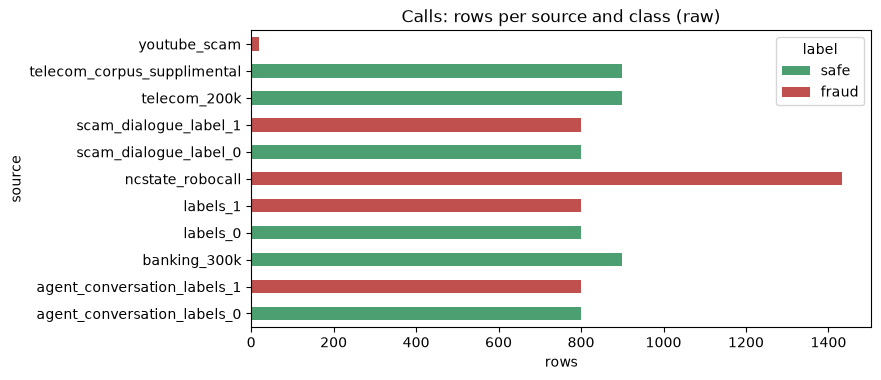

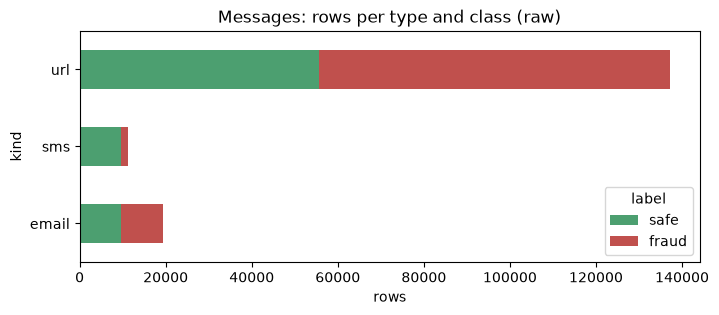

In [5]:
plot_class_balance(calls, 'source', 'Calls: rows per source and class (raw)', 'step1_calls_balance')
plot_class_balance(msgs, 'kind', 'Messages: rows per type and class (raw)', 'step1_msgs_balance');

## Decision: how a call is paired with a message, email or link
Implemented in `toadwatch/pairing.py`:
1. A call is paired with a message-side item of the **same label** (fraud+fraud, safe+safe) - the TOAD pattern.
2. Pairing is done **inside** each train/val/test split, so nothing crosses splits.
3. Each call is used once; message items are drawn evenly from SMS, email and URL, and classes are balanced inside every type, so the message type says nothing about the label.
4. The draw uses the fixed seed (42).

No public dataset has real call+message pairs, so this is a reconstruction - stated as a limitation of the study.

## Still to do outside the code
- [ ] Send the data requests to DACO and to Puerto Rico university faculty.
- [ ] Put the cases they return in `data/external/pr_cases.csv` (columns: case_id, call_transcript, message_text, label, source, notes). Aim for 20-30 per class; it becomes the secondary Puerto Rico test.